<a href="https://colab.research.google.com/github/bhargavanarasimhaai24/Freight-rate-prediction/blob/main/main.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

!pip install catboost -q
from catboost import CatBoostRegressor

import os
from IPython.display import Image, display

#Data Loading

In [ ]:
train = pd.read_csv("train-test.csv")
validation = pd.read_csv("validation.csv")
template = pd.read_csv("validation-predictions-template.csv")
december = pd.read_csv("december-chart-inputs.csv")

print("TRAIN:", train.shape)
print("VALIDATION:", validation.shape)
print("TEMPLATE:", template.shape)
print("DECEMBER:", december.shape)

TRAIN: (48000, 14)
VALIDATION: (12000, 13)
TEMPLATE: (12000, 2)
DECEMBER: (31, 7)


#EDA

In [ ]:
for name, df in {"TRAIN": train, "VALIDATION": validation, "DECEMBER": december}.items():
    print(f"\n{'='*20} {name} {'='*20}")
    print("Columns:", df.columns.tolist())
    print(df.dtypes)
    print("\nFirst 3 rows:")
    print(df.head(3).to_string(index=False))


==================== TRAIN ====================
Columns: ['load_id', 'pickup', 'delivery', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance', 'equipment', 'weight', 'date', 'market_index', 'quote_signal', 'posted_rate']
load_id          object
pickup           object
delivery         object
pickup_lat      float64
pickup_lon      float64
delivery_lat    float64
delivery_lon    float64
distance        float64
equipment        object
weight          float64
date             object
market_index    float64
quote_signal    float64
posted_rate     float64
dtype: object

First 3 rows:
  load_id       pickup     delivery  pickup_lat  pickup_lon  delivery_lat  delivery_lon  distance equipment  weight       date  market_index  quote_signal  posted_rate
TR-000001     Richmond    Baltimore    38.09122   -76.78906      38.16908     -72.74564     274.3   Dry Van 30658.0 2025-01-01       0.95684       2.39595       645.41
TR-000002     Richmond Philadelphia    38.09122   -76.789

In [ ]:
for name, df in {"TRAIN": train, "VALIDATION": validation, "DECEMBER": december}.items():
    print(f"    {name}")
    print(f'   ---------')
    missing = df.isnull().sum()
    print(missing[missing > 0])
    print("Total missing:", df.isnull().sum().sum())

    TRAIN
   ---------
weight          300
market_index    374
dtype: int64
Total missing: 674
    VALIDATION
   ---------
weight          165
market_index    249
dtype: int64
Total missing: 414
    DECEMBER
   ---------
predicted_rate    31
dtype: int64
Total missing: 31


Conclusion: Missing values are limited. Investigate median imputation rather than deleting rows.

In [ ]:
for name, df in {"TRAIN": train, "VALIDATION": validation, "DECEMBER": december}.items():
    df["date"] = pd.to_datetime(df["date"])
    print(f"\n{name}")
    print("Start:", df["date"].min())
    print("End:", df["date"].max())
    print("Unique dates:", df["date"].nunique())
    print("\nRows per month:")
    print(df["date"].dt.to_period("M").value_counts().sort_index())


TRAIN
Start: 2025-01-01 00:00:00
End: 2025-10-31 00:00:00
Unique dates: 304

Rows per month:
date
2025-01    4918
2025-02    4337
2025-03    5036
2025-04    4819
2025-05    4913
2025-06    4783
2025-07    4912
2025-08    4759
2025-09    4670
2025-10    4853
Freq: M, Name: count, dtype: int64

VALIDATION
Start: 2025-11-01 00:00:00
End: 2025-12-31 00:00:00
Unique dates: 61

Rows per month:
date
2025-11    5836
2025-12    6164
Freq: M, Name: count, dtype: int64

DECEMBER
Start: 2025-12-01 00:00:00
End: 2025-12-31 00:00:00
Unique dates: 31

Rows per month:
date
2025-12    31
Freq: M, Name: count, dtype: int64


Conc: Train on January–August and validate on September–October. After choosing the model, retrain on all January–October data and predict the 12,000 unseen November–December loads.

In [ ]:
print(train["posted_rate"].describe())

print("\nTarget percentiles:")
print(train["posted_rate"].quantile([0, 0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99, 1]))

print("\nCorrelation with numerical features:")
print(train.select_dtypes(include=np.number).corr()["posted_rate"].sort_values(ascending=False))

count    48000.000000
mean      2373.980682
std       1486.493245
min         57.220000
25%       1251.555000
50%       2030.760000
75%       3330.750000
max      25533.000000
Name: posted_rate, dtype: float64

Target percentiles:
0.00       57.2200
0.01      327.1688
0.05      599.7385
0.25     1251.5550
0.50     2030.7600
0.75     3330.7500
0.95     4953.7665
0.99     5972.8340
1.00    25533.0000
Name: posted_rate, dtype: float64

Correlation with numerical features:
posted_rate     1.000000
distance        0.908519
weight          0.034840
market_index    0.034165
quote_signal   -0.039858
pickup_lat     -0.090873
delivery_lat   -0.091970
pickup_lon     -0.255058
delivery_lon   -0.257086
Name: posted_rate, dtype: float64


Key observations:

- The maximum posted rate is considerably higher than the 99th percentile, so extreme values need further investigation.
- Distance has a strong positive correlation with posted rate (0.909).
- Other numerical features have weak individual correlations, but may still contribute through nonlinear relationships or interactions.

###Rate Factor Investigation

In [ ]:
train["rate_per_mile"] = train["posted_rate"] / train["distance"]

print(train[["distance", "posted_rate", "rate_per_mile", "market_index", "quote_signal"]].describe())

print("\nCorrelation with rate per mile:")
print(
    train[["rate_per_mile", "weight", "market_index", "quote_signal"]].corr()["rate_per_mile"].sort_values(ascending=False)
)

           distance   posted_rate  rate_per_mile  market_index  quote_signal
count  48000.000000  48000.000000   48000.000000  47626.000000  48000.000000
mean    1135.856654   2373.980682       2.215347      1.083387      2.062468
std      728.564416   1486.493245       0.583887      0.168091      0.291391
min       70.000000     57.220000       0.333709      0.676390      0.692280
25%      550.400000   1251.555000       1.986974      0.949670      1.891030
50%      953.300000   2030.760000       2.145348      1.055800      2.055750
75%     1645.525000   3330.750000       2.342696      1.219590      2.221685
max     3439.800000  25533.000000      14.125294      1.467780      3.610350

Correlation with rate per mile:
rate_per_mile    1.000000
market_index     0.083478
weight           0.074517
quote_signal     0.049342
Name: rate_per_mile, dtype: float64


In [ ]:
# From the above o/p rate per mile and quote signal has similar stats but correlation is less, so checking if posted_rate = distance * quote_signal?

train["rate_factor"] = (
    train["posted_rate"] /
    (train["distance"] * train["quote_signal"])
)

print("Rate factor statistics:")
print(train["rate_factor"].describe())

print("\nRate factor correlations:")
print(train[["rate_factor", "market_index", "weight", "quote_signal"]]
      .corr()["rate_factor"].sort_values(ascending=False))

print("\nRate factor by equipment:")
print(train.groupby("equipment")["rate_factor"].agg(
    ["count", "mean", "median", "std", "min", "max"]
).round(4))

Rate factor statistics:
count    48000.000000
mean         1.099564
std          0.372845
min          0.146885
25%          0.989975
50%          1.003992
75%          1.090748
max         11.371649
Name: rate_factor, dtype: float64

Rate factor correlations:
rate_factor     1.000000
market_index    0.124190
weight          0.065485
quote_signal   -0.482957
Name: rate_factor, dtype: float64

Rate factor by equipment:
           count    mean  median     std     min      max
equipment                                                
Dry Van    27202  1.0481  1.0002  0.3148  0.1469   8.7553
Flatbed     8753  1.1324  1.0073  0.3915  0.1719   9.1576
Reefer     12045  1.1919  1.0117  0.4512  0.1818  11.3716


The median rate factor is close to 1.004, but its high variability and negative correlation with quote_signal indicate that there is no simple fixed pricing formula.

I will test rate_factor as an alternative target during model evaluation and compare its performance with the original target model.

###Checking this for December dataset, which doesn't have same columns

In [ ]:
print("Unique pickup cities:", train["pickup"].nunique())
print("Unique delivery cities:", train["delivery"].nunique())
print("Equipment types:", train["equipment"].unique())

print("\nDuplicate rows:", train.duplicated().sum())
print("Duplicate load IDs:", train["load_id"].duplicated().sum())

Unique pickup cities: 64
Unique delivery cities: 64
Equipment types: ['Dry Van' 'Reefer' 'Flatbed']

Duplicate rows: 0
Duplicate load IDs: 0


### Data Quality Investigation

In [ ]:
print("WEIGHT QUALITY CHECK")
print("Missing weights:", train["weight"].isna().sum())
print("Zero weights:", (train["weight"] == 0).sum())
print("Negative weights:", (train["weight"] < 0).sum())
print("Minimum weight:", train["weight"].min())
print("Maximum weight:", train["weight"].max())

print("\nRATE FACTOR OUTLIERS")
for threshold in [2, 3, 5, 8]:
    print(
        f"Rate factor > {threshold}:",
        (train["rate_factor"] > threshold).sum()
    )

print("\nTARGET OUTLIERS")
for threshold in [10000, 15000, 20000]:
    print(
        f"Posted rate > ${threshold}:",
        (train["posted_rate"] > threshold).sum()
    )

print("\nNEGATIVE WEIGHT EXAMPLES")
print(
    train[train["weight"] < 0][
        ["pickup", "delivery", "distance", "equipment",
         "weight", "market_index", "quote_signal", "posted_rate"]
    ].head(10).to_string(index=False)
)


WEIGHT QUALITY CHECK
Missing weights: 300
Zero weights: 0
Negative weights: 292
Minimum weight: -47500.0
Maximum weight: 47500.0

RATE FACTOR OUTLIERS
Rate factor > 2: 1116
Rate factor > 3: 334
Rate factor > 5: 45
Rate factor > 8: 6

TARGET OUTLIERS
Posted rate > $10000: 103
Posted rate > $15000: 24
Posted rate > $20000: 9

NEGATIVE WEIGHT EXAMPLES
     pickup     delivery  distance equipment   weight  market_index  quote_signal  posted_rate
   Amarillo       Dayton    1334.2    Reefer -36559.0       0.96102       2.11777      2831.27
     Fresno       Tucson     496.2   Dry Van -26670.0       0.96903       2.13155      1046.92
   Columbia      Raleigh     411.3    Reefer -20003.0       0.94800       2.31682       959.15
 Greensboro      Lubbock    1317.4    Reefer -23981.0       1.00820       2.13918      2836.00
    Madison   Providence    1331.1   Dry Van -41397.0       0.94787       1.91867      2522.54
Albuquerque       Albany    2438.3    Reefer -37215.0       0.96575       1.969

High-value observations are relatively rare. I will retain them initially rather than remove them without evidence. MAE and RMSE will help evaluate their effect on model performance.

In [ ]:
print("WEIGHT DISTRIBUTION")
print(train["weight"].describe())

print("\nWEIGHT CORRELATION WITH TARGET")
train["abs_weight"] = train["weight"].abs()

print(
    train[["weight", "abs_weight", "posted_rate"]]
    .corr().round(4)
)

print("\nNEGATIVE VS POSITIVE WEIGHT")
train["weight_sign"] = train["weight"] < 0

display(
    train.groupby("weight_sign")[
        ["weight", "abs_weight", "posted_rate"]
    ].agg(["count", "mean", "median"]).round(3)
)

print("\nVALIDATION WEIGHT QUALITY")
print("Missing:", validation["weight"].isna().sum())
print("Negative:", (validation["weight"] < 0).sum())
print("Zero:", (validation["weight"] == 0).sum())
print("Minimum:", validation["weight"].min())
print("Maximum:", validation["weight"].max())


WEIGHT DISTRIBUTION
count    47700.000000
mean     31028.844004
std       9391.440620
min     -47500.000000
25%      25800.000000
50%      31436.500000
75%      37018.000000
max      47500.000000
Name: weight, dtype: float64

WEIGHT CORRELATION WITH TARGET
             weight  abs_weight  posted_rate
weight       1.0000      0.8388       0.0348
abs_weight   0.8388      1.0000       0.0413
posted_rate  0.0348      0.0413       1.0000

NEGATIVE VS POSITIVE WEIGHT


weight                     abs_weight                      \
             count       mean   median      count       mean   median   
weight_sign                                                             
False        47408  31415.359  31493.5      47408  31415.359  31493.5   
True           292 -31724.195 -31821.5        292  31724.195  31821.5   

            posted_rate                     
                  count      mean   median  
weight_sign                                 
False             47708  2373.884  2031.16  
True                292  2389.786  1994.96


VALIDATION WEIGHT QUALITY
Missing: 165
Negative: 145
Zero: 0
Minimum: -47500.0
Maximum: 47500.0


Negative weights are not physically meaningful for shipment weight. Their absolute magnitudes are within the normal observed range, so I will use absolute weight values.

Missing weights will be filled using the median calculated from the training data.

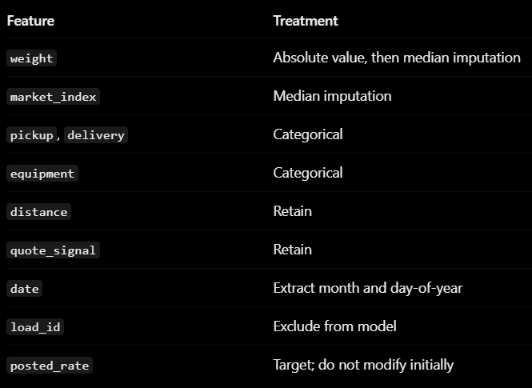

#Model Training and Evaluation

##Chronological split

Split is:
- Training: January–August (38,477 rows).
- (Local) Validation: September–October (9,523 rows).

In [ ]:
# Convert date
train["date"] = pd.to_datetime(train["date"])

# Chronological split
fit_data = train[train["date"] < "2025-09-01"].copy()
val_data = train[
    (train["date"] >= "2025-09-01") &
    (train["date"] <= "2025-10-31")
].copy()

print("Training period:",
      fit_data["date"].min(), "to", fit_data["date"].max())
print("Validation period:",
      val_data["date"].min(), "to", val_data["date"].max())

print("\nTraining shape:", fit_data.shape)
print("Validation shape:", val_data.shape)

print("\nTraining target mean:", fit_data["posted_rate"].mean())
print("Validation target mean:", val_data["posted_rate"].mean())

print("\nTraining months:")
print(fit_data["date"].dt.month.value_counts().sort_index())

print("\nValidation months:")
print(val_data["date"].dt.month.value_counts().sort_index())


Training period: 2025-01-01 00:00:00 to 2025-08-31 00:00:00
Validation period: 2025-09-01 00:00:00 to 2025-10-31 00:00:00

Training shape: (38477, 18)
Validation shape: (9523, 18)

Training target mean: 2369.40951191621
Validation target mean: 2392.4501690643706

Training months:
date
1    4918
2    4337
3    5036
4    4819
5    4913
6    4783
7    4912
8    4759
Name: count, dtype: int64

Validation months:
date
9     4670
10    4853
Name: count, dtype: int64


##Feature preparation

Based on the picture pasted after EDA

In [ ]:
# Features used by the model
FEATURES = [
    "pickup",
    "delivery",
    "equipment",
    "distance",
    "weight",
    "market_index",
    "quote_signal",
    "month",
    "day_of_year",
    "day_of_week"
]

CAT_FEATURES = ["pickup", "delivery", "equipment"]

def prepare_features(df):
    df = df.copy()

    # Correct negative weights
    df["weight"] = df["weight"].abs()

    # Extract date features
    df["date"] = pd.to_datetime(df["date"])
    df["month"] = df["date"].dt.month
    df["day_of_year"] = df["date"].dt.dayofyear
    df["day_of_week"] = df["date"].dt.dayofweek

    # Ensure categorical columns have consistent types
    for col in CAT_FEATURES:
        df[col] = df[col].fillna("Unknown").astype(str)

    return df[FEATURES]

X_train = prepare_features(fit_data)
X_val = prepare_features(val_data)

y_train = fit_data["posted_rate"]
y_val = val_data["posted_rate"]

# Impute numerical missing values using training medians
NUM_FEATURES = [
    "distance", "weight", "market_index", "quote_signal",
    "month", "day_of_year", "day_of_week"
]

medians = X_train[NUM_FEATURES].median()

X_train[NUM_FEATURES] = X_train[NUM_FEATURES].fillna(medians)
X_val[NUM_FEATURES] = X_val[NUM_FEATURES].fillna(medians)

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Remaining training missing values:", X_train.isna().sum().sum())
print("Remaining validation missing values:", X_val.isna().sum().sum())


Training features: (38477, 10)
Validation features: (9523, 10)
Remaining training missing values: 0
Remaining validation missing values: 0


##Model Fitting

In [ ]:
def evaluate_model(name, model, X_val, y_val):
    predictions = model.predict(X_val)

    mae = mean_absolute_error(y_val, predictions)
    rmse = np.sqrt(mean_squared_error(y_val, predictions))
    r2 = r2_score(y_val, predictions)

    print(f"\n{name}")
    print("-" * 35)
    print(f"MAE:  ${mae:.2f}")
    print(f"RMSE: ${rmse:.2f}")
    print(f"R²:    {r2:.4f}")

    return predictions, {"Model": name, "MAE": mae, "RMSE": rmse, "R2": r2}

baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train[["distance"]], y_train)

baseline_predictions, baseline_results = evaluate_model(
    "Dummy Baseline", baseline, X_val[["distance"]], y_val
)


Dummy Baseline
-----------------------------------
MAE:  $1178.80
RMSE: $1526.23
R²:    -0.0002


**Model 1 - CatBoost**

In [ ]:
cat_model = CatBoostRegressor(
    iterations=1000,
    learning_rate=0.05,
    depth=8,
    loss_function="RMSE",
    eval_metric="MAE",
    random_seed=42,
    verbose=200,
    early_stopping_rounds=100
)

cat_model.fit(
    X_train,
    y_train,
    cat_features=CAT_FEATURES,
    eval_set=(X_val, y_val),
    use_best_model=True
)

cat_predictions, cat_results = evaluate_model(
    "CatBoost", cat_model, X_val, y_val
)

0:	learn: 1102.5945804	test: 1123.8874382	best: 1123.8874382 (0)	total: 114ms	remaining: 1m 53s
200:	learn: 109.4020273	test: 120.6594916	best: 120.5540631 (174)	total: 21.6s	remaining: 1m 25s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 120.5540631
bestIteration = 174

Shrink model to first 175 iterations.

CatBoost
-----------------------------------
MAE:  $120.55
RMSE: $634.44
R²:    0.8272


In [ ]:
results = pd.DataFrame([baseline_results, cat_results])
display(results)

,Model,MAE,RMSE,R2
0,Dummy Baseline,1178.803281,1526.226298,-0.000228
1,CatBoost,120.554064,634.440854,0.827160


##Investigating prediction errors

In [ ]:
diagnostics = val_data[
    ["distance", "posted_rate"]
].copy()

diagnostics["predicted_rate(ŷ)"] = cat_predictions
diagnostics["absolute_error"] = (
    diagnostics["posted_rate"] - diagnostics["predicted_rate(ŷ)"]
).abs()

print("Best iteration:", cat_model.best_iteration_)

print("\nAbsolute error distribution:")
print(diagnostics["absolute_error"].describe(
    percentiles=[0.50, 0.90, 0.95, 0.99]
).round(2))

diagnostics["distance_group"] = pd.cut(
    diagnostics["distance"],
    bins=[0, 500, 1000, 1500, 2000, np.inf],
    labels=["0-500", "500-1000", "1000-1500",
            "1500-2000", "2000+"]
)

print("\nError by distance:")
print(
    diagnostics.groupby("distance_group", observed=True)
    ["absolute_error"].agg(["count", "mean"]).round(2)
)

Best iteration: 174

Absolute error distribution:
count     9523.00
mean       120.55
std        622.91
min          0.01
50%         49.05
90%        144.61
95%        204.95
99%       1538.27
max      16322.11
Name: absolute_error, dtype: float64

Error by distance:
                count    mean
distance_group               
0-500            2090   60.53
500-1000         2972   87.43
1000-1500        1760  126.89
1500-2000        1167  182.69
2000+            1534  211.96


Conc: Heteroscadasticity is observed

Solution: A small number of high-value loads produce disproportionately large prediction errors. I will test a log transformation to check whether it improves performance.

In [ ]:
for name, df in [("Training", fit_data), ("Validation", val_data)]:
    print(f"\n{name}:")
    print("Rows:", len(df))
    print("Posted rate above $10,000:",
          (df["posted_rate"] > 10000).sum())
    print("Posted rate above $20,000:",
          (df["posted_rate"] > 20000).sum())

    print(df["posted_rate"].describe(
        percentiles=[0.90, 0.95, 0.99]
    ).round(2))



Training:
Rows: 38477
Posted rate above $10,000: 79
Posted rate above $20,000: 7
count    38477.00
mean      2369.41
std       1476.50
min         57.22
50%       2026.04
90%       4350.75
95%       4930.68
99%       5968.61
max      25533.00
Name: posted_rate, dtype: float64

Validation:
Rows: 9523
Posted rate above $10,000: 24
Posted rate above $20,000: 2
count     9523.00
mean      2392.45
std       1526.13
min        104.38
50%       2044.32
90%       4426.26
95%       5044.47
99%       6030.01
max      20361.89
Name: posted_rate, dtype: float64


In [ ]:
log_model = CatBoostRegressor(
    iterations=1000,
    learning_rate=0.05,
    depth=8,
    loss_function="RMSE",
    eval_metric="MAE",
    random_seed=42,
    verbose=200,
    early_stopping_rounds=100
)

log_model.fit(
    X_train,
    np.log1p(y_train),
    cat_features=CAT_FEATURES,
    eval_set=(X_val, np.log1p(y_val)),
    use_best_model=True
)

# Convert predictions back to original dollar scale
log_predictions = np.expm1(log_model.predict(X_val))

log_mae = mean_absolute_error(y_val, log_predictions)
log_rmse = np.sqrt(mean_squared_error(y_val, log_predictions))
log_r2 = r2_score(y_val, log_predictions)

print("\nLOG-TRANSFORMED CATBOOST")
print("Best iteration:", log_model.best_iteration_)
print(f"MAE:  ${log_mae:.2f}")
print(f"RMSE: ${log_rmse:.2f}")
print(f"R²:    {log_r2:.4f}")

0:	learn: 0.5111239	test: 0.5175608	best: 0.5175608 (0)	total: 67.4ms	remaining: 1m 7s
200:	learn: 0.0414011	test: 0.0494485	best: 0.0492002 (115)	total: 21s	remaining: 1m 23s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.04920021215
bestIteration = 115

Shrink model to first 116 iterations.

LOG-TRANSFORMED CATBOOST
Best iteration: 115
MAE:  $124.80
RMSE: $638.66
R²:    0.8249


Conc: The log-transformed model did not improve performance. The original target model achieved lower MAE and RMSE, so I'll keep the original target as our preferred approach and mov on to another experiment: predicting the rate factor.

In [ ]:
# Create comparable subsets
train_check = fit_data.copy()
val_check = val_data.copy()

for df in [train_check, val_check]:
    df["rate_per_mile"] = df["posted_rate"] / df["distance"]

    df["rate_factor"] = (
        df["posted_rate"] /
        (df["distance"] * df["quote_signal"])
    )

    df["high_rate"] = df["posted_rate"] > 10000

# Compare high-rate and normal-rate loads
for name, df in [
    ("TRAINING", train_check),
    ("VALIDATION", val_check)
]:
    print(f"\n{'='*20} {name} {'='*20}")

    print("\nHigh-rate proportion:")
    print(df["high_rate"].value_counts())

    print("\nFeature comparison:")
    display(
        df.groupby("high_rate")[
            ["posted_rate", "distance", "weight",
             "market_index", "quote_signal",
             "rate_per_mile", "rate_factor"]
        ].median().round(3)
    )

    print("\nHigh-rate loads by equipment:")
    print(
        df[df["high_rate"]]["equipment"]
        .value_counts()
    )


==================== TRAINING ====================

High-rate proportion:
high_rate
False    38398
True        79
Name: count, dtype: int64

Feature comparison:


,posted_rate,distance,weight,market_index,quote_signal,rate_per_mile,rate_factor
high_rate,,,,,,,
False,2023.065,953.4,31405.0,1.120,2.054,2.141,1.004
True,12422.220,1851.3,31247.0,1.155,2.000,7.810,3.863



High-rate loads by equipment:
equipment
Dry Van    41
Reefer     22
Flatbed    16
Name: count, dtype: int64

==================== VALIDATION ====================

High-rate proportion:
high_rate
False    9499
True       24
Name: count, dtype: int64

Feature comparison:


,posted_rate,distance,weight,market_index,quote_signal,rate_per_mile,rate_factor
high_rate,,,,,,,
False,2040.47,943.30,31562.0,0.928,2.065,2.161,1.004
True,13462.11,1826.65,31883.5,0.953,2.050,8.052,4.053



High-rate loads by equipment:
equipment
Dry Van    16
Reefer      6
Flatbed     2
Name: count, dtype: int64


Conc: The extreme freight rates appear to form a rare pricing pattern that our current features do not explain well.

We cannot conclude that high-rate loads are invalid observations. They may be legitimate loads with pricing factors not represented in our available features.

##Next experiment: Rate-Factor Model Experiment

predict rate factor instead of posted rate

**Model 2 - CatBoost with Rate_factor prediction**

In [ ]:

# Create rate-factor targets
train_factor = (
    y_train / (X_train["distance"] * X_train["quote_signal"])
)

val_factor = (
    y_val / (X_val["distance"] * X_val["quote_signal"])
)

factor_model = CatBoostRegressor(
    iterations=1000,
    learning_rate=0.05,
    depth=8,
    loss_function="RMSE",
    eval_metric="MAE",
    random_seed=42,
    verbose=200,
    early_stopping_rounds=100
)

factor_model.fit(
    X_train,
    train_factor,
    cat_features=CAT_FEATURES,
    eval_set=(X_val, val_factor),
    use_best_model=True
)

# Reconstruct predicted freight rates
predicted_factor = factor_model.predict(X_val)

factor_predictions = (
    X_val["distance"].to_numpy()
    * X_val["quote_signal"].to_numpy()
    * predicted_factor
)

factor_mae = mean_absolute_error(y_val, factor_predictions)
factor_rmse = np.sqrt(mean_squared_error(y_val, factor_predictions))
factor_r2 = r2_score(y_val, factor_predictions)

print("\nRATE-FACTOR MODEL")
print("Best iteration:", factor_model.best_iteration_)
print(f"MAE:  ${factor_mae:.2f}")
print(f"RMSE: ${factor_rmse:.2f}")
print(f"R²:    {factor_r2:.4f}")


0:	learn: 0.1761409	test: 0.1950039	best: 0.1950039 (0)	total: 112ms	remaining: 1m 51s
200:	learn: 0.0481135	test: 0.0625473	best: 0.0625132 (197)	total: 10.1s	remaining: 40.2s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.06240672237
bestIteration = 205

Shrink model to first 206 iterations.

RATE-FACTOR MODEL
Best iteration: 205
MAE:  $114.18
RMSE: $633.28
R²:    0.8278


In [ ]:
factor_diagnostics = pd.DataFrame({
    "actual": y_val,
    "predicted": factor_predictions
})

factor_diagnostics["absolute_error"] = (
    factor_diagnostics["actual"]
    - factor_diagnostics["predicted"]
).abs()

factor_diagnostics["high_rate"] = (
    factor_diagnostics["actual"] > 10000
)

print("Error by target segment:")
display(
    factor_diagnostics.groupby("high_rate").agg(
        count=("actual", "size"),
        actual_mean=("actual", "mean"),
        predicted_mean=("predicted", "mean"),
        MAE=("absolute_error", "mean")
    ).round(2)
)

Error by target segment:


,count,actual_mean,predicted_mean,MAE
high_rate,,,,
False,9499,2363.11,2351.71,88.58
True,24,14003.43,3759.56,10243.87


     Feature  Importance
quote_signal   54.206844
    distance   15.915874
   equipment    7.321553
 day_of_year    4.651254
market_index    3.684297
       month    3.496940
    delivery    3.249149
      weight    3.124385
      pickup    3.088078
 day_of_week    1.261624


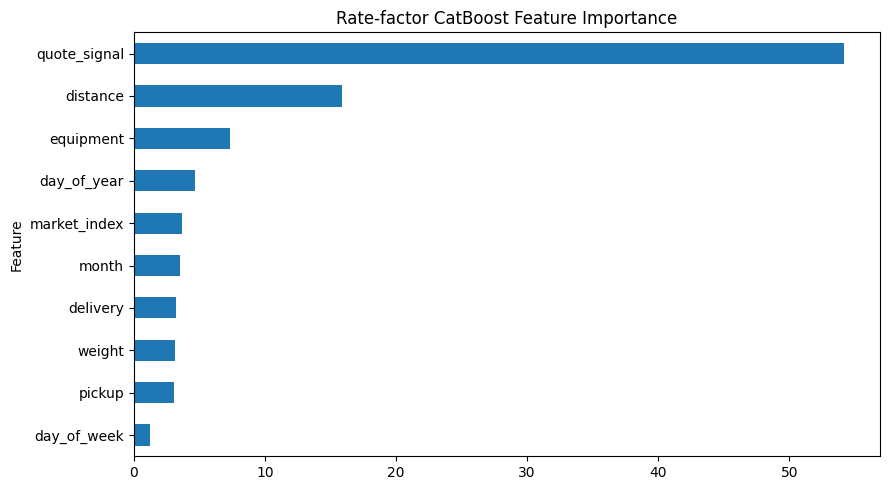

In [ ]:

factor_importance = pd.DataFrame({
    "Feature": FEATURES,
    "Importance": factor_model.feature_importances_
}).sort_values("Importance", ascending=False)

print(factor_importance.to_string(index=False))

factor_importance.sort_values("Importance").plot(
    x="Feature",
    y="Importance",
    kind="barh",
    legend=False,
    figsize=(9, 5),
    title="Rate-factor CatBoost Feature Importance"
)

import matplotlib.pyplot as plt
plt.tight_layout()
plt.show()


**Model 3 - Ensemble Learning**

In [ ]:

# Blend the predictions of both CatBoost models

blend_results = []

for w in [0.25, 0.50, 0.75]:
    blended_predictions = (
        w * cat_predictions +
        (1 - w) * factor_predictions
    )

    blend_results.append({
        "Direct Model Weight": w,
        "MAE": mean_absolute_error(y_val, blended_predictions),
        "RMSE": np.sqrt(mean_squared_error(y_val, blended_predictions)),
        "R2": r2_score(y_val, blended_predictions)
    })

blend_results = pd.DataFrame(blend_results)

# Include existing rate-factor model as benchmark
print("Existing Rate-factor CatBoost:")
print(f"MAE: ${mean_absolute_error(y_val, factor_predictions):.2f}")

print("\nBLENDING RESULTS:")
display(blend_results.round(4))


Existing Rate-factor CatBoost:
MAE: $114.18

BLENDING RESULTS:


,Direct Model Weight,MAE,RMSE,R2
0,0.25,111.6078,632.8769,0.8280
1,0.50,111.9885,632.9338,0.8280
2,0.75,115.1651,633.4555,0.8277


##Final training: use all 48,000 labelled rows

Our validation experiment used January–August for fitting and September–October for evaluation.

Now that we have selected the model, we can train on all January–October data.

The Ensemble model(Model 3) achieved the best validation MAE. I will retrain it using all 48,000 labelled rows with 206 iterations, selected from the chronological validation experiment.

In [ ]:

# FINAL TRAINING: DIRECT + RATE-FACTOR CATBOOST BLEND

# Prepare all labelled training data
X_full = prepare_features(train)
y_full = train["posted_rate"].copy()

# Prepare Spotter's validation data
X_final = prepare_features(validation)

# Impute missing values using full training-data medians
final_medians = X_full[NUM_FEATURES].median()

X_full[NUM_FEATURES] = X_full[NUM_FEATURES].fillna(final_medians)
X_final[NUM_FEATURES] = X_final[NUM_FEATURES].fillna(final_medians)


# 1. Direct CatBoost model
final_direct_model = CatBoostRegressor(
    iterations=175,
    learning_rate=0.05,
    depth=8,
    loss_function="RMSE",
    random_seed=42,
    verbose=200
)

final_direct_model.fit(
    X_full,
    y_full,
    cat_features=CAT_FEATURES
)

direct_final_predictions = final_direct_model.predict(X_final)


# 2. Rate-factor CatBoost model
rate_factor = (
    y_full / (X_full["distance"] * X_full["quote_signal"])
)

final_factor_model = CatBoostRegressor(
    iterations=206,
    learning_rate=0.05,
    depth=8,
    loss_function="RMSE",
    random_seed=42,
    verbose=200
)

final_factor_model.fit(
    X_full,
    rate_factor,
    cat_features=CAT_FEATURES
)

predicted_factor = final_factor_model.predict(X_final)

factor_final_predictions = (
    X_final["distance"].to_numpy()
    * X_final["quote_signal"].to_numpy()
    * predicted_factor
)


# 3. Blend: 25% direct + 75% rate-factor
final_predictions = (
    0.25 * direct_final_predictions
    + 0.75 * factor_final_predictions
)

# Ensure all predictions are positive
final_predictions = np.maximum(final_predictions, 0.01)


# 4. Save final submission CSV
validation_predictions = pd.DataFrame({
    "load_id": validation["load_id"],
    "predicted_rate": final_predictions
})

validation_predictions.to_csv(
    "validation_predictions.csv",
    index=False
)

print("Training rows:", len(X_full))
print("Prediction rows:", len(X_final))
print("Minimum prediction:", final_predictions.min())
print("Maximum prediction:", final_predictions.max())
print("\nSaved validation_predictions.csv")
print(validation_predictions.head())


0:	learn: 1427.7323605	total: 33.6ms	remaining: 5.84s
174:	learn: 579.4824990	total: 4.69s	remaining: 0us
0:	learn: 0.3647328	total: 83.9ms	remaining: 17.2s
200:	learn: 0.2591659	total: 13s	remaining: 324ms
205:	learn: 0.2588788	total: 13.3s	remaining: 0us
Training rows: 48000
Prediction rows: 12000
Minimum prediction: 211.85901280510683
Maximum prediction: 7247.539838046281

Saved validation_predictions.csv
     load_id  predicted_rate
0  TE-000001      809.944864
1  TE-000002     5125.613977
2  TE-000003     5464.826978
3  TE-000004     4162.439285
4  TE-000005     1816.286768


In [ ]:
# Read back the saved file
check_submission = pd.read_csv("validation_predictions.csv")

assert check_submission.shape == (12000, 2)
assert list(check_submission.columns) == [
    "load_id", "predicted_rate"
]
assert check_submission["load_id"].equals(
    validation["load_id"].reset_index(drop=True)
)
assert np.isfinite(check_submission["predicted_rate"]).all()
assert (check_submission["predicted_rate"] > 0).all()

print("CSV saved and verified successfully!")
print("\nFile shape:", check_submission.shape)
print(check_submission.head())

CSV saved and verified successfully!

File shape: (12000, 2)
     load_id  predicted_rate
0  TE-000001      809.944864
1  TE-000002     5125.613977
2  TE-000003     5464.826978
3  TE-000004     4162.439285
4  TE-000005     1816.286768


#December Forecasting

**Model 2 - CatBoost with Rate_factor prediction**

In [ ]:

DEC_FEATURES = [
    "pickup",
    "delivery",
    "equipment",
    "distance",
    "weight",
    "month",
    "day_of_year",
    "day_of_week"
]

DEC_CAT_FEATURES = ["pickup", "delivery", "equipment"]

def prepare_dec_features(df):
    df = df.copy()
    df["date"] = pd.to_datetime(df["date"])

    df["weight"] = df["weight"].abs()

    df["month"] = df["date"].dt.month
    df["day_of_year"] = df["date"].dt.dayofyear
    df["day_of_week"] = df["date"].dt.dayofweek

    for col in DEC_CAT_FEATURES:
        df[col] = df[col].fillna("Unknown").astype(str)

    return df[DEC_FEATURES]

X_train_dec = prepare_dec_features(fit_data)
X_val_dec = prepare_dec_features(val_data)

dec_num_features = [
    "distance", "weight", "month",
    "day_of_year", "day_of_week"
]

dec_medians = X_train_dec[dec_num_features].median()

X_train_dec[dec_num_features] = (
    X_train_dec[dec_num_features].fillna(dec_medians)
)

X_val_dec[dec_num_features] = (
    X_val_dec[dec_num_features].fillna(dec_medians)
)

In [ ]:

# Create distance-factor targets
train_factor_dec = (
    y_train / X_train_dec["distance"]
)

val_factor_dec = (
    y_val / X_val_dec["distance"]
)


# Train CatBoost
dec_factor_model = CatBoostRegressor(
    iterations=1000,
    learning_rate=0.05,
    depth=8,
    loss_function="RMSE",
    eval_metric="MAE",
    random_seed=42,
    verbose=200,
    early_stopping_rounds=100
)

dec_factor_model.fit(
    X_train_dec,
    train_factor_dec,
    cat_features=DEC_CAT_FEATURES,
    eval_set=(X_val_dec, val_factor_dec),
    use_best_model=True
)


# Predict distance factor
predicted_dec_factor = dec_factor_model.predict(X_val_dec)


# Reconstruct predicted freight rates
dec_factor_predictions = (
    X_val_dec["distance"].to_numpy()
    * predicted_dec_factor
)


# Calculate performance on actual freight rates
dec_factor_mae = mean_absolute_error(
    y_val, dec_factor_predictions
)

dec_factor_rmse = np.sqrt(
    mean_squared_error(y_val, dec_factor_predictions)
)

dec_factor_r2 = r2_score(
    y_val, dec_factor_predictions
)


print("\nDECEMBER DISTANCE-FACTOR MODEL — VALIDATION PERFORMANCE")
print("Best iteration:", dec_factor_model.best_iteration_)
print(f"MAE:  ${dec_factor_mae:.2f}")
print(f"RMSE: ${dec_factor_rmse:.2f}")
print(f"R²:    {dec_factor_r2:.4f}")


0:	learn: 0.2557428	test: 0.2570279	best: 0.2570279 (0)	total: 58.5ms	remaining: 58.5s
200:	learn: 0.1027141	test: 0.1075109	best: 0.1069837 (177)	total: 11.2s	remaining: 44.4s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.106983747
bestIteration = 177

Shrink model to first 178 iterations.

DECEMBER DISTANCE-FACTOR MODEL — VALIDATION PERFORMANCE
Best iteration: 177
MAE:  $109.54
RMSE: $632.13
R²:    0.8284


**Model 3 - Ensemble Learning**

In [ ]:
# DECEMBER-COMPATIBLE ENSEMBLE: CHRONOLOGICAL VALIDATION

# These features are available in the December input file
DEC_FEATURES = [
    f for f in FEATURES
    if f not in ["market_index", "quote_signal"]
]

DEC_CAT_FEATURES = [
    f for f in CAT_FEATURES
    if f in DEC_FEATURES
]

DEC_NUM_FEATURES = [
    f for f in DEC_FEATURES
    if f not in DEC_CAT_FEATURES
]


# Prepare chronological training and validation data
X_train_dec = prepare_features(fit_data)[DEC_FEATURES].copy()
X_val_dec = prepare_features(val_data)[DEC_FEATURES].copy()

y_train_dec = fit_data["posted_rate"].copy()
y_val_dec = val_data["posted_rate"].copy()

# Impute using training medians only
dec_medians = X_train_dec[DEC_NUM_FEATURES].median()

X_train_dec[DEC_NUM_FEATURES] = (
    X_train_dec[DEC_NUM_FEATURES].fillna(dec_medians)
)
X_val_dec[DEC_NUM_FEATURES] = (
    X_val_dec[DEC_NUM_FEATURES].fillna(dec_medians)
)


# MODEL 1: Direct posted-rate prediction
dec_direct_model = CatBoostRegressor(
    iterations=175,
    learning_rate=0.05,
    depth=8,
    loss_function="RMSE",
    random_seed=42,
    verbose=False
)

dec_direct_model.fit(
    X_train_dec,
    y_train_dec,
    cat_features=DEC_CAT_FEATURES
)

dec_direct_pred = dec_direct_model.predict(X_val_dec)


# MODEL 2: Predict rate per unit of distance
dec_factor_pred = dec_factor_predictions


# Compare individual models and different blend weights
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("DIRECT MODEL")
print("MAE:", mean_absolute_error(y_val_dec, dec_direct_pred))

print("\nDISTANCE-FACTOR MODEL")
print("MAE:", mean_absolute_error(y_val_dec, dec_factor_pred))

print("\nBLEND RESULTS")
best_weight = None
best_mae = float("inf")

for direct_weight in [0, 0.25, 0.5, 0.75, 1]:
    blended_dec = (
        direct_weight * dec_direct_pred
        + (1 - direct_weight) * dec_factor_pred
    )

    mae = mean_absolute_error(y_val_dec, blended_dec)
    rmse = np.sqrt(mean_squared_error(y_val_dec, blended_dec))
    r2 = r2_score(y_val_dec, blended_dec)

    print(
        f"Direct {direct_weight:.2f} | "
        f"Factor {1-direct_weight:.2f} | "
        f"MAE: {mae:.4f} | RMSE: {rmse:.4f} | R2: {r2:.4f}"
    )

    if mae < best_mae:
        best_mae = mae
        best_weight = direct_weight

print("\nBEST DIRECT WEIGHT:", best_weight)
print("BEST FACTOR WEIGHT:", 1 - best_weight)
print("BEST BLEND MAE:", best_mae)

DIRECT MODEL
MAE: 123.61371795221687

DISTANCE-FACTOR MODEL
MAE: 109.54306504890678

BLEND RESULTS
Direct 0.00 | Factor 1.00 | MAE: 109.5431 | RMSE: 632.1335 | R2: 0.8284
Direct 0.25 | Factor 0.75 | MAE: 110.5405 | RMSE: 632.2107 | R2: 0.8284
Direct 0.50 | Factor 0.50 | MAE: 113.4532 | RMSE: 632.6460 | R2: 0.8281
Direct 0.75 | Factor 0.25 | MAE: 117.9408 | RMSE: 633.4389 | R2: 0.8277
Direct 1.00 | Factor 0.00 | MAE: 123.6137 | RMSE: 634.5878 | R2: 0.8271

BEST DIRECT WEIGHT: 0
BEST FACTOR WEIGHT: 1
BEST BLEND MAE: 109.54306504890678


##Final training: use all 48,000 labelled rows

We can observe that **Model 2 performs better** than Model 3 (Ensemble)

In [ ]:

# FINAL DECEMBER PREDICTIONS: DISTANCE-FACTOR CATBOOST

# 1. Prepare all 48,000 labelled training rows
X_full_dec = prepare_dec_features(train)
y_full_dec = train["posted_rate"].copy()

# 2. Calculate medians from full training data
final_dec_medians = X_full_dec[dec_num_features].median()

X_full_dec[dec_num_features] = (
    X_full_dec[dec_num_features].fillna(final_dec_medians)
)

# 3. Prepare December inputs
december_df = december.copy()

X_december = prepare_dec_features(december_df)

X_december[dec_num_features] = (
    X_december[dec_num_features].fillna(final_dec_medians)
)

# 4. Create distance-factor training target
final_dec_factor = (
    y_full_dec / X_full_dec["distance"]
)

# 5. Train final distance-factor model
final_dec_model = CatBoostRegressor(
    iterations=206,
    learning_rate=0.05,
    depth=8,
    loss_function="RMSE",
    random_seed=42,
    verbose=100
)

final_dec_model.fit(
    X_full_dec,
    final_dec_factor,
    cat_features=DEC_CAT_FEATURES
)

# 6. Predict distance factor
predicted_dec_factor = final_dec_model.predict(X_december)

# 7. Convert distance factor back to posted_rate
december_predictions = (
    predicted_dec_factor
    * X_december["distance"].to_numpy()
)

# Ensure positive predictions
december_predictions = np.maximum(
    december_predictions, 0.01
)

# 8. Update December predictions
december_df["predicted_rate"] = december_predictions

print("Training rows:", len(X_full_dec))
print("December predictions:", len(december_predictions))
print("Minimum:", december_predictions.min())
print("Maximum:", december_predictions.max())
print()
print(december_df[["date", "predicted_rate"]].head())

0:	learn: 0.5783652	total: 69.4ms	remaining: 14.2s
100:	learn: 0.5126199	total: 6.89s	remaining: 7.16s
200:	learn: 0.5077817	total: 11.1s	remaining: 276ms
205:	learn: 0.5077057	total: 11.2s	remaining: 0us
Training rows: 48000
December predictions: 31
Minimum: 868.433898406573
Maximum: 885.4303405444775

        date  predicted_rate
0 2025-12-01      868.433898
1 2025-12-02      874.079783
2 2025-12-03      885.430341
3 2025-12-04      884.149106
4 2025-12-05      879.745424


In [ ]:

december_df["predicted_rate"] = december_predictions

# Preserve the exact required column order
december_df = december_df[
    ["pickup", "delivery", "distance", "equipment",
     "weight", "date", "predicted_rate"]
]

assert len(december_df) == 31
assert december_df["predicted_rate"].notna().all()
assert np.isfinite(december_df["predicted_rate"]).all()
assert (december_df["predicted_rate"] > 0).all()

december_df.to_csv("december_chart_inputs.csv", index=False)

print(december_df.to_string(index=False))
print("\nSaved december_chart_inputs.csv")


   pickup   delivery  distance equipment  weight       date  predicted_rate
Lexington Fort Wayne       360   Dry Van   32000 2025-12-01      868.433898
Lexington Fort Wayne       360   Dry Van   32000 2025-12-02      874.079783
Lexington Fort Wayne       360   Dry Van   32000 2025-12-03      885.430341
Lexington Fort Wayne       360   Dry Van   32000 2025-12-04      884.149106
Lexington Fort Wayne       360   Dry Van   32000 2025-12-05      879.745424
Lexington Fort Wayne       360   Dry Van   32000 2025-12-06      870.455362
Lexington Fort Wayne       360   Dry Van   32000 2025-12-07      869.859042
Lexington Fort Wayne       360   Dry Van   32000 2025-12-08      868.433898
Lexington Fort Wayne       360   Dry Van   32000 2025-12-09      874.079783
Lexington Fort Wayne       360   Dry Van   32000 2025-12-10      885.430341
Lexington Fort Wayne       360   Dry Van   32000 2025-12-11      884.149106
Lexington Fort Wayne       360   Dry Van   32000 2025-12-12      879.745424
Lexington Fo

#Scorer Validation

In [ ]:
!python score.py \
  --predictions validation_predictions.csv \
  --december-predictions december_chart_inputs.csv

Validated 12,000 final predictions.
Validated 31 fixed December predictions.
Created chart: scorer_results/candidate_december.png
Final validation metrics are calculated by Spotter after submission.


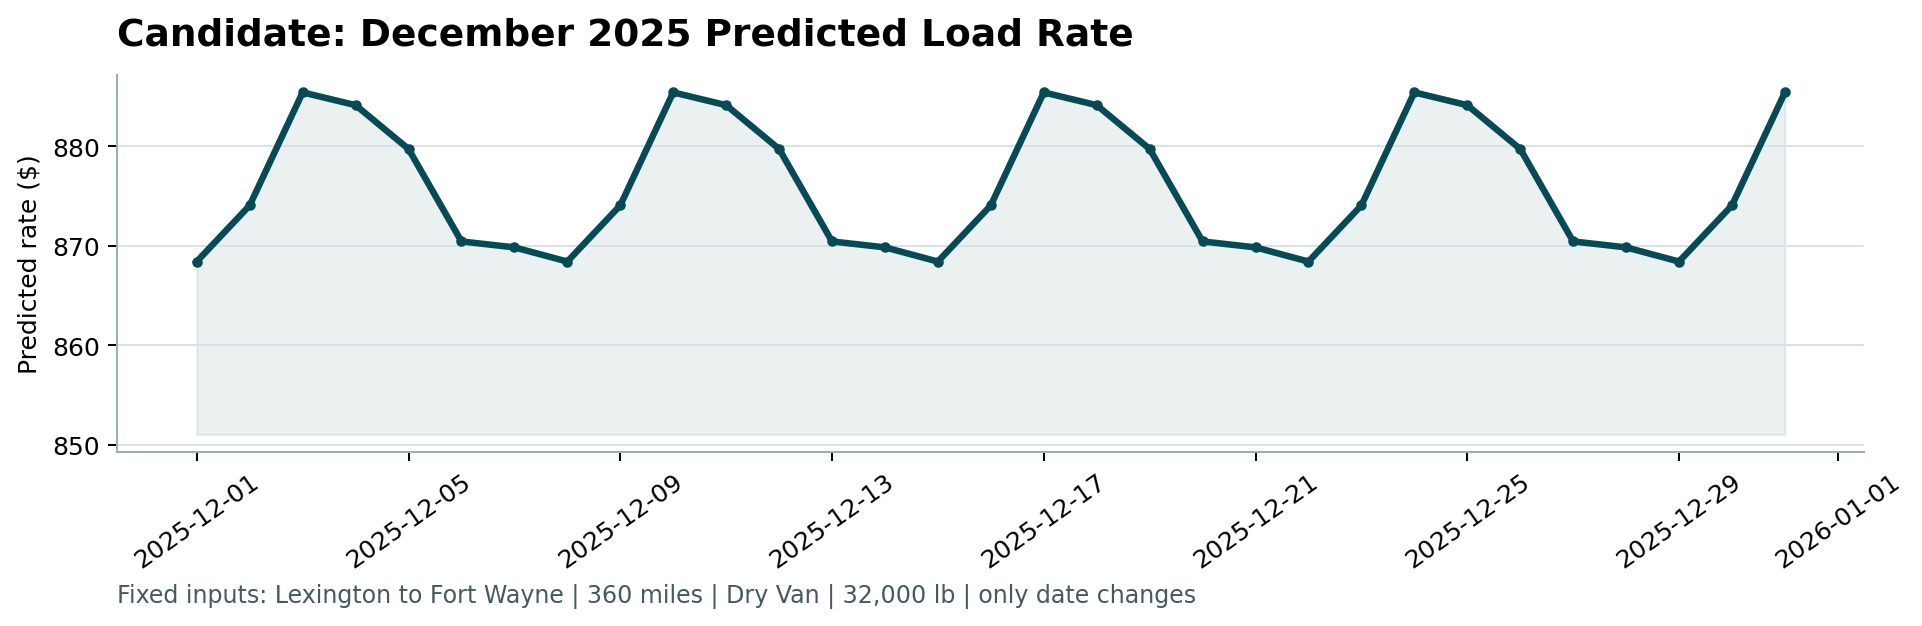

In [ ]:
display(Image("/content/scorer_results/candidate_december.png"))